# 01 — Chargement des données et analyse exploratoire

**Challenge Data ENS n°160 (Enedis)** : compléter les valeurs manquantes de courbes de consommation électrique au pas de 30 minutes.

Objectif de ce notebook : comprendre **ce qu'il faut prédire** avant de modéliser.
- Quelles courbes, à quels niveaux, avec quelles régularités (jour, semaine) ?
- Quelle est la forme des trous : longueur, position, répartition entre courbes ?
- Le train est-il représentatif du test ?
- Où l'interpolation linéaire (benchmark) échoue-t-elle, et les courbes se ressemblent-elles assez pour justifier un KNN ?

Chaque section se termine par un encadré **Constat → conséquence pour la modélisation**. Toutes les figures utilisent le style du projet (`enedis_imputation.viz`) : leur titre énonce la conclusion, le sous-titre gris décrit ce qui est tracé.

| Section | Contenu |
|---|---|
| a | Vue d'ensemble |
| b | Les courbes |
| c | Structure des trous |
| d | Train vs test |
| e | Erreur du benchmark |
| f | Les courbes se ressemblent-elles ? |
| — | Synthèse |

In [1]:
# Imports et configuration
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter
from scipy.stats import ks_2samp, spearmanr

from enedis_imputation import SEED
from enedis_imputation.data import PROJECT_ROOT, load_test, load_train, mae_on_holes
from enedis_imputation.holes import LENGTH_LABELS, hole_length_per_point, hole_runs, length_bucket
from enedis_imputation.viz import PALETTE as P
from enedis_imputation.viz import (
    method_color,
    plot_imputation,
    save_fig,
    set_conclusion,
    set_style,
)

set_style()  # style unique du projet : fond blanc, grille légère, export 200 dpi
rng = np.random.default_rng(SEED)  # graine fixée : tirages reproductibles
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")


def fmt_hour(h: float) -> str:
    """Formate une heure décimale (4.5 → '4 h 30')."""
    return f"{int(h)} h {int(round(h % 1 * 60)):02d}".replace(" h 00", " h")

In [2]:
# Chargement : premier appel = lecture des CSV (~15 s) puis cache .npy ; ensuite ~0,1 s.
X_full, X_holed, y = load_train()
T_full, T_holed = load_test()

# Masques des valeurs à prédire (vrai = manquant), en numpy pour limiter la mémoire
mask = X_holed.isna().to_numpy()
T_mask = T_holed.isna().to_numpy()

## a. Vue d'ensemble

In [3]:
# Dimensions et empreinte mémoire (float32 = 4 octets par valeur)
frames = {
    "X_train — complètes": X_full,
    "X_train — trouées": X_holed,
    "y_train": y,
    "X_test — complètes": T_full,
    "X_test — trouées": T_holed,
}
pd.DataFrame(
    {
        "pas de temps": [f.shape[0] for f in frames.values()],
        "courbes": [f.shape[1] for f in frames.values()],
        "mémoire (Mo)": [f.to_numpy().nbytes / 1e6 for f in frames.values()],
    },
    index=frames.keys(),
)

,pas de temps,courbes,mémoire (Mo)
X_train — complètes,1057,20000,84.560
X_train — trouées,1057,1000,4.228
y_train,1057,1000,4.228
X_test — complètes,1057,37140,157.028
X_test — trouées,1057,1000,4.228


In [4]:
# Période et régularité du pas de temps
idx = X_full.index
steps = idx.to_series().diff().dropna().value_counts()
print(f"Début : {idx[0]} ({idx[0].day_name()})   Fin : {idx[-1]} ({idx[-1].day_name()})")
print(f"{len(idx)} pas de temps = {(len(idx) - 1) / 48:.0f} jours × 48 + 1")
print("Pas de temps observés :", dict(steps))
print("Index identiques train/test :", X_full.index.equals(T_full.index))

Début : 2023-01-09 00:00:00 (Monday)   Fin : 2023-01-31 00:00:00 (Tuesday)
1057 pas de temps = 22 jours × 48 + 1
Pas de temps observés : {Timedelta('0 days 00:30:00'): np.int64(1056)}
Index identiques train/test : True


In [5]:
# NaN dans les courbes censées être complètes
def nan_report(F: pd.DataFrame) -> pd.DataFrame:
    """Résume les courbes 'complètes' qui contiennent des NaN."""
    nan = np.isnan(F.to_numpy())
    touched = np.flatnonzero(nan.any(axis=0))
    runs = hole_runs(nan[:, touched])
    return pd.DataFrame(
        {
            "courbe": F.columns[touched],
            "NaN": nan[:, touched].sum(axis=0),
            "part manquante": nan[:, touched].mean(axis=0),
            "nb de trous": runs.groupby("curve").size().to_numpy(),
            "plus long trou": runs.groupby("curve")["length"].max().to_numpy(),
        }
    )


for name, F in [("train", X_full), ("test", T_full)]:
    rep = nan_report(F)
    print(
        f"{name} : {rep['NaN'].sum()} NaN répartis sur {len(rep)} courbe(s) "
        f"sur {F.shape[1]} ({len(rep) / F.shape[1]:.3%})"
    )
    display(rep)

train : 620 NaN répartis sur 1 courbe(s) sur 20000 (0.005%)


,courbe,NaN,part manquante,nb de trous,plus long trou
0,7986541023,620,0.587,93,47


test : 4133 NaN répartis sur 4 courbe(s) sur 37140 (0.011%)


,courbe,NaN,part manquante,nb de trous,plus long trou
0,1250968743,1055,0.998,3,530
1,1753428906,1001,0.947,31,250
2,7132659048,1021,0.966,16,664
3,7813042569,1056,0.999,2,556


In [6]:
# NaN de y_train : où sont-ils ? y est-il cohérent avec X_holed sur les points observés ?
y_arr, xh_arr = y.to_numpy(), X_holed.to_numpy()
y_nan = np.isnan(y_arr)
print(f"NaN dans y_train : {y_nan.sum()}, dont dans les trous : {(y_nan & mask).sum()}")
print("Colonnes concernées :", y.columns[y_nan.any(axis=0)].tolist())
print(
    "y == X_holed sur les points observés :",
    np.array_equal(y_arr[~mask], xh_arr[~mask], equal_nan=True),
)

# Format de soumission
sub = pd.read_csv(PROJECT_ROOT / "data" / "raw" / "sample_submission.csv", index_col=0)
print(
    "\nsample_submission :",
    sub.shape,
    "| colonnes = X_test trouées :",
    sub.columns.equals(T_holed.columns),
    "| index identique :",
    pd.to_datetime(sub.index).equals(T_holed.index),
)
print(
    "Valeurs du fichier exemple = interpolation linéaire ?",
    np.allclose(sub.to_numpy(), T_holed.interpolate(limit_direction="both").to_numpy()),
)
del sub, xh_arr

NaN dans y_train : 1056, dont dans les trous : 1056
Colonnes concernées : ['holed_192']
y == X_holed sur les points observés : True

sample_submission : (1057, 1000) | colonnes = X_test trouées : True | index identique : True


Valeurs du fichier exemple = interpolation linéaire ? False


### Constat → conséquence pour la modélisation

**Constat**
- Les 5 tableaux partagent le même index : 1 057 pas de 30 min, du lundi 9 janvier 00:00 au mardi 31 janvier 00:00 (22 jours + 1 point). Aucun pas ne manque, aucun n'est en double, et train et test ont exactement les mêmes horodates.
- En float32, l'ensemble tient en ~255 Mo (dont 157 Mo pour les courbes complètes du test).
- Les NaN des courbes « complètes » sont **concentrés** :
  - en train, **1 seule courbe** (620 NaN, 59 % de la courbe) ;
  - en test, **4 courbes**, vides à 95–99,9 % (4 133 NaN).
- Les 1 056 NaN de `y_train` sont tous dans **`holed_192`**, la courbe vide à 99,9 % : sa vérité est inconnue, elle ne pèse donc qu'un point dans la MAE.
- `y_train` est identique à `X_train` sur les points observés. Toute l'information nouvelle est sur les positions trouées.
- `sample_submission.csv` a le bon format (colonnes et index des courbes trouées du test), mais ses valeurs sont arbitraires : ce n'est **pas** le benchmark.

**→ Conséquence**
- Retirer ces 5 courbes « complètes » incomplètes du réservoir de voisins (KNN) et des données d'apprentissage : elles fausseraient les distances et n'apportent rien.
- Toujours évaluer avec `mae_on_holes`, qui exclut les NaN de `y`.
- La mémoire suffit pour charger les données. Elle deviendra un problème pour les calculs croisés (distances entre 1 000 et 37 000 courbes), à faire **par blocs**.

## b. Les courbes

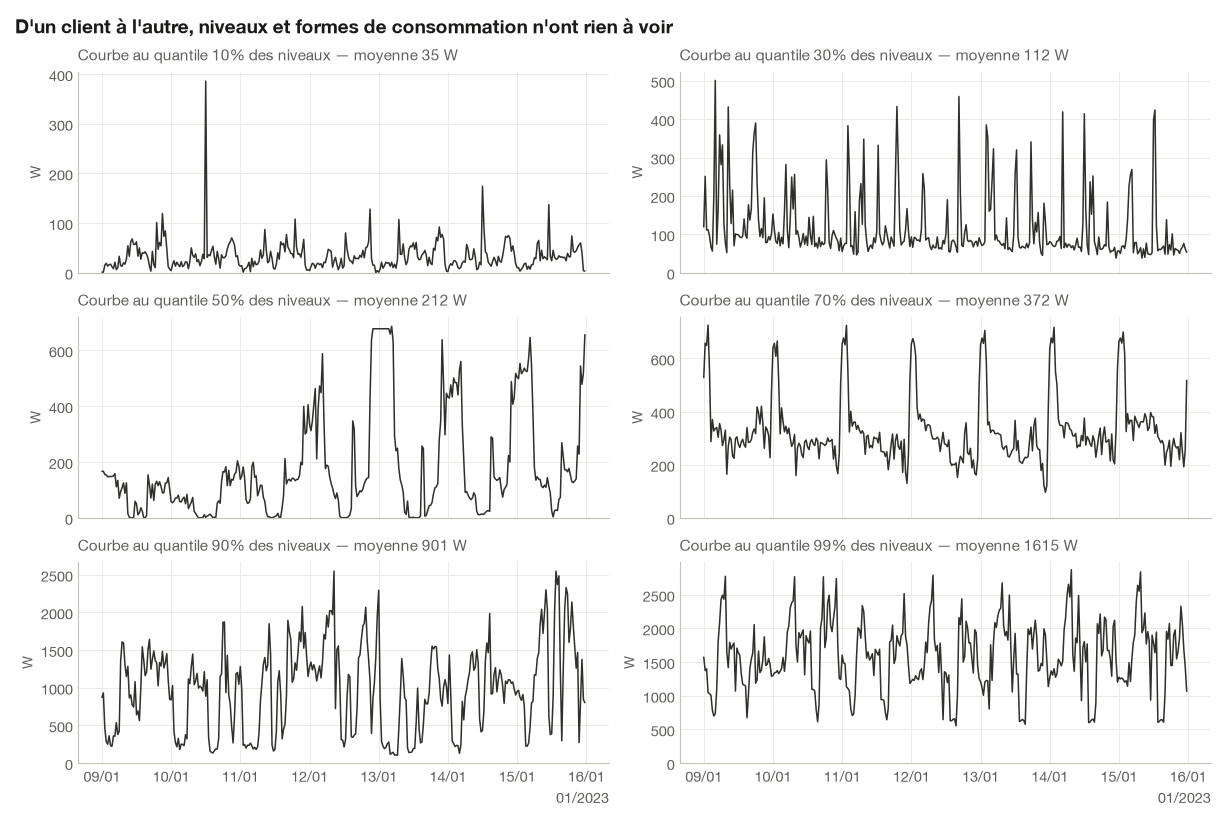

In [7]:
# Niveau moyen de chaque courbe complète (en W)
levels = X_full.mean()  # pandas ignore les NaN
week = slice("2023-01-09", "2023-01-15")  # lundi → dimanche

# 6 courbes types : celles dont le niveau est le plus proche de quantiles choisis
quantiles = [0.10, 0.30, 0.50, 0.70, 0.90, 0.99]
chosen = [(levels - levels.quantile(q)).abs().idxmin() for q in quantiles]

fig, axes = plt.subplots(3, 2, figsize=(12, 8), sharex=True)
for ax, q, col in zip(axes.flat, quantiles, chosen, strict=True):
    s = X_full.loc[week, col]
    ax.plot(s.index, s.to_numpy(), color=P["true"], lw=1.1)
    ax.set_title(f"Courbe au quantile {q:.0%} des niveaux — moyenne {levels[col]:.0f} W")
    ax.set_ylabel("W")
    ax.set_ylim(bottom=0)
set_conclusion(fig, "D'un client à l'autre, niveaux et formes de consommation n'ont rien à voir")
save_fig(fig, "b1_courbes_types");

Courbes identiquement nulles : 700 (3.5%)
Niveau moyen <  1 W :   870 (4.3%)
Niveau moyen < 10 W :  1234 (6.2%)
Niveau moyen < 50 W :  2776 (13.9%)
Valeurs négatives : 0 courbe(s)


,count,mean,std,min,1%,10%,25%,50%,75%,90%,99%,max
niveau moyen (W),"20,000.000",343.984,368.724,0.000,0.000,35.091,90.190,212.403,446.417,900.670,"1,614.854","2,674.736"


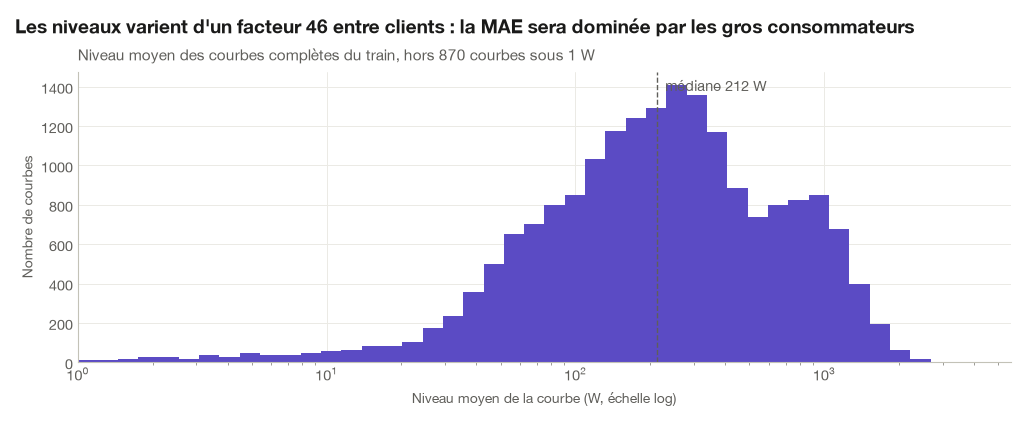

In [8]:
# Distribution des niveaux moyens et part de courbes nulles
is_zero = X_full.abs().max() == 0
print(f"Courbes identiquement nulles : {is_zero.sum()} ({is_zero.mean():.1%})")
for thr in [1, 10, 50]:
    print(f"Niveau moyen < {thr:>2} W : {(levels < thr).sum():>5} ({(levels < thr).mean():.1%})")
print(f"Valeurs négatives : {(X_full.min() < 0).sum()} courbe(s)")
display(
    levels.describe(percentiles=[0.01, 0.1, 0.25, 0.5, 0.75, 0.9, 0.99])
    .to_frame("niveau moyen (W)")
    .T
)

fig, ax = plt.subplots(figsize=(10, 4))
pos = levels[levels > 0]
ax.hist(pos, bins=np.logspace(np.log10(pos.min()), np.log10(pos.max()), 80), color=P["data"])
ax.set_xscale("log")
ax.set_xlim(left=1)
ax.axvline(levels.median(), color=P["ink_secondary"], ls="--", lw=1)
ax.annotate(
    f"médiane {levels.median():.0f} W",
    (levels.median(), 1),
    xycoords=("data", "axes fraction"),
    xytext=(6, -14),
    textcoords="offset points",
    color=P["ink_secondary"],
)
ax.set_xlabel("Niveau moyen de la courbe (W, échelle log)")
ax.set_ylabel("Nombre de courbes")
ax.set_title(
    f"Niveau moyen des courbes complètes du train, hors {(levels < 1).sum()} courbes sous 1 W"
)
ratio = levels.quantile(0.99) / levels.quantile(0.10)
set_conclusion(
    fig,
    f"Les niveaux varient d'un facteur {ratio:.0f} entre clients : "
    "la MAE sera dominée par les gros consommateurs",
)
save_fig(fig, "b2_niveaux");

,Semaine,Week-end
min,0.839,0.853
idxmin,4.500,4.500
max,1.214,1.233
idxmax,19.000,19.000


Écart week-end / semaine entre 9 h et 16 h : +12.7%


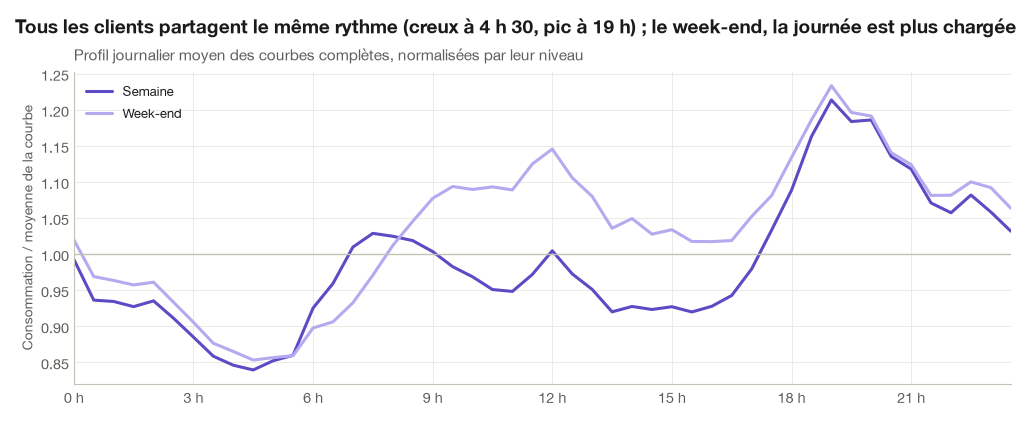

In [9]:
# Profils moyens : chaque courbe est divisée par son niveau moyen pour que les gros
# consommateurs ne dominent pas la moyenne. On exclut les courbes quasi nulles (< 10 W).
active = levels.index[levels >= 10]
norm_mean = (X_full[active] / levels[active]).mean(axis=1)  # profil normalisé, par pas de temps

hour = idx.hour + idx.minute / 60
weekend = idx.day_of_week >= 5
daily = pd.DataFrame(
    {
        "Semaine": norm_mean[~weekend].groupby(hour[~weekend]).mean(),
        "Week-end": norm_mean[weekend].groupby(hour[weekend]).mean(),
    }
)

fig, ax = plt.subplots(figsize=(10, 4))
for name, color in [("Semaine", P["data"]), ("Week-end", P["data_light"])]:
    ax.plot(daily.index, daily[name], color=color, lw=2.2, label=name)
ax.axhline(1, color=P["axis"], lw=1)
ax.set_xticks(range(0, 25, 3), [f"{h} h" for h in range(0, 25, 3)])
ax.set_xlim(0, 23.5)
ax.set_ylabel("Consommation / moyenne de la courbe")
ax.set_title("Profil journalier moyen des courbes complètes, normalisées par leur niveau")
ax.legend(loc="upper left")
set_conclusion(
    fig,
    f"Tous les clients partagent le même rythme (creux à {fmt_hour(daily['Semaine'].idxmin())}, "
    f"pic à {fmt_hour(daily['Semaine'].idxmax())}) ; le week-end, la journée est plus chargée",
)
save_fig(fig, "b3_profil_journalier")
display(daily.agg(["min", "idxmin", "max", "idxmax"]))
day_hours = (daily.index >= 9) & (daily.index < 16)
print(
    "Écart week-end / semaine entre 9 h et 16 h : "
    f"{daily.loc[day_hours, 'Week-end'].mean() / daily.loc[day_hours, 'Semaine'].mean() - 1:+.1%}"
)

Écart week-end / semaine : +4.9%
Jour le plus haut / le plus bas de la période : +28.9%


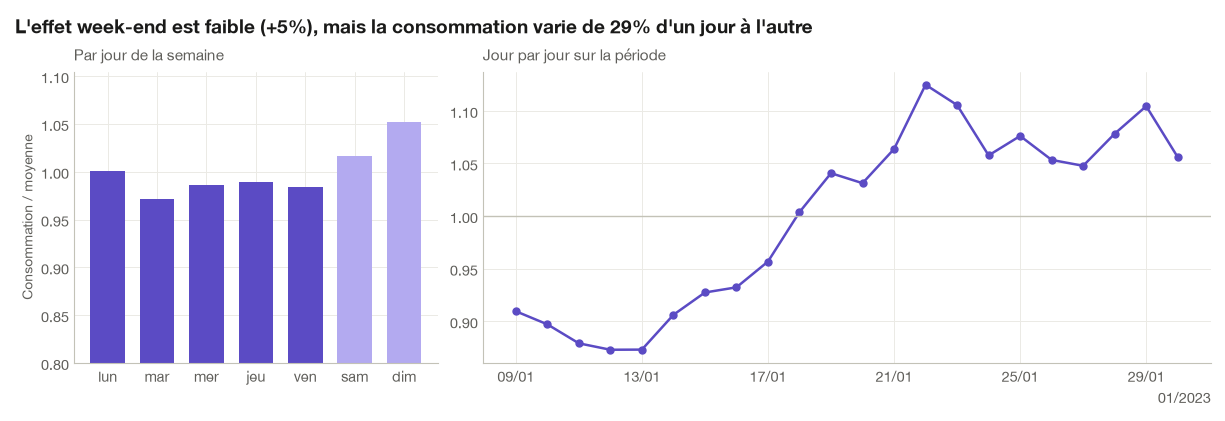

In [10]:
# Profil hebdomadaire et évolution sur la période
days_fr = ["lun", "mar", "mer", "jeu", "ven", "sam", "dim"]
by_dow = norm_mean.groupby(idx.day_of_week).mean()
by_day = norm_mean.groupby(idx.normalize()).mean().iloc[:-1]  # le 31/01 n'a qu'un point
weekend_effect = by_dow[5:].mean() / by_dow[:5].mean() - 1
day_spread = by_day.max() / by_day.min() - 1

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4), width_ratios=[1, 2])
ax1.bar(days_fr, by_dow.to_numpy(), color=[P["data"]] * 5 + [P["data_light"]] * 2, width=0.7)
ax1.set_ylim(0.8, by_dow.max() * 1.05)
ax1.set_title("Par jour de la semaine")
ax1.set_ylabel("Consommation / moyenne")
ax2.plot(by_day.index, by_day.to_numpy(), color=P["data"], marker="o", ms=5)
ax2.axhline(1, color=P["axis"], lw=1)
ax2.set_title("Jour par jour sur la période")
set_conclusion(
    fig,
    f"L'effet week-end est faible ({weekend_effect:+.0%}), "
    f"mais la consommation varie de {day_spread:.0%} d'un jour à l'autre",
)
save_fig(fig, "b4_profil_hebdo")
print(f"Écart week-end / semaine : {weekend_effect:+.1%}")
print(f"Jour le plus haut / le plus bas de la période : {day_spread:+.1%}")

,30 min,1 h,3 h,6 h,12 h,24 h,7 j
autocorrélation médiane,0.709,0.523,0.210,0.072,0.064,0.457,0.170


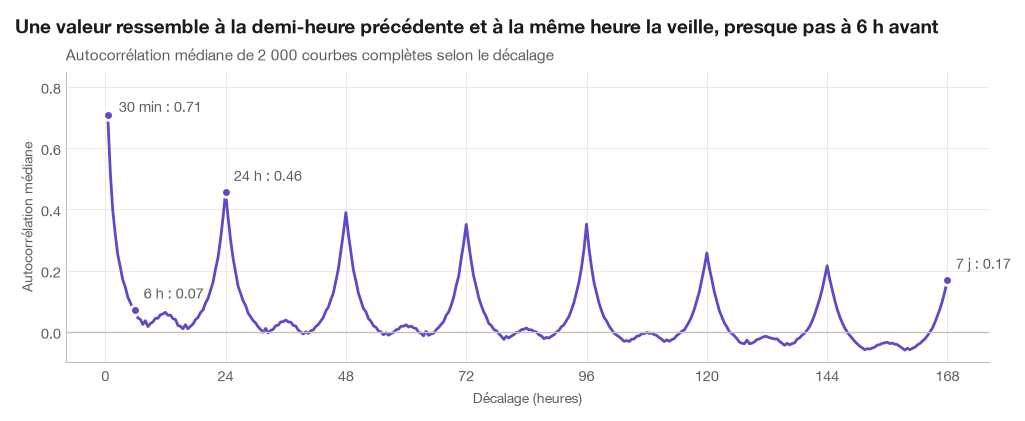

In [11]:
# Autocorrélation : à quelle vitesse une courbe « oublie » son passé ?
# Sur 2 000 courbes complètes tirées au hasard (sans NaN, non constantes).
sample = X_full.iloc[:, rng.choice(X_full.shape[1], 2000, replace=False)].to_numpy(np.float64)
sample = sample[:, ~np.isnan(sample).any(axis=0) & (sample.std(axis=0) > 0)]
Z = (sample - sample.mean(axis=0)) / sample.std(axis=0)
lags = np.arange(1, 337)
acf = np.array([np.median((Z[k:] * Z[:-k]).mean(axis=0)) for k in lags])
del sample, Z

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(lags / 2, acf, color=P["data"], lw=2)
for k, lab in [(1, "30 min"), (12, "6 h"), (48, "24 h"), (336, "7 j")]:
    ax.plot(k / 2, acf[k - 1], "o", color=P["data"], ms=7, mec="white", mew=2)
    ax.annotate(
        f"{lab} : {acf[k - 1]:.2f}",
        (k / 2, acf[k - 1]),
        xytext=(8, 2) if k == 1 else (6, 8),
        textcoords="offset points",
        color=P["ink_secondary"],
    )
ax.axhline(0, color=P["axis"], lw=1)
ax.set_ylim(-0.1, 0.85)
ax.set_xlabel("Décalage (heures)")
ax.set_ylabel("Autocorrélation médiane")
ax.set_xticks(range(0, 169, 24))
ax.set_title("Autocorrélation médiane de 2 000 courbes complètes selon le décalage")
set_conclusion(
    fig,
    "Une valeur ressemble à la demi-heure précédente et à la même heure la veille, "
    "presque pas à 6 h avant",
)
save_fig(fig, "b5_autocorrelation")
pd.Series(
    acf[[0, 1, 5, 11, 23, 47, 335]],
    index=["30 min", "1 h", "3 h", "6 h", "12 h", "24 h", "7 j"],
    name="autocorrélation médiane",
).to_frame().T

### Constat → conséquence pour la modélisation

**Constat**
- **Niveaux très hétérogènes**, distribués à peu près selon une loi log-normale :
  - médiane 212 W ;
  - 10 % des courbes sous 35 W ;
  - 1 % au-dessus de 1,6 kW.
- **3,5 % des courbes sont identiquement nulles**, 6,2 % ont un niveau moyen inférieur à 10 W. Aucune valeur n'est négative.
- **Profil journalier marqué, commun à toutes les courbes** : creux vers 4 h 30 (0,84 × la moyenne de la courbe), pic à 19 h (1,21 ×).
- **Effet week-end modéré** : +4,9 % en moyenne, mais concentré en journée. Entre 9 h et 16 h, le week-end est plus chargé de 13 % (présence au domicile), alors que la nuit et la soirée sont quasi identiques.
- **Forte composante commune d'un jour à l'autre** : +29 % entre le jour le plus chargé et le moins chargé de la période. C'est janvier : le chauffage électrique suit une météo partagée par tous les clients.
- **Autocorrélation** :
  - **0,71 à 30 min**, mais seulement 0,21 à 3 h et ≈ 0,07 à 6–12 h ;
  - elle **remonte à 0,46 à 24 h**, et vaut 0,17 à 7 jours.
  
  Une valeur ressemble à ses voisines immédiates et à la même heure la veille, mais presque plus à ce qui s'est passé 6 h plus tôt.

**→ Conséquence**
- La mémoire courte explique les forces et faiblesses de l'interpolation : excellente sur 1–2 points, elle se dégrade dès que le trou dépasse quelques pas, car elle relie alors deux points devenus quasi indépendants.
- Pour les longs trous, l'information utile est **« à la même heure »** :
  - même créneau la veille et le lendemain pour la courbe (décalage ±48) ;
  - profil horaire et composante commune, apportés par les autres courbes (KNN).
  
  Ce seront les variables d'entrée naturelles du LightGBM, avec un indicateur week-end (qui modifie la forme de la journée).
- L'hétérogénéité des niveaux fait que **la MAE est dominée par les gros consommateurs**. À tester : chercher les voisins sur des courbes mises à l'échelle, puis remettre au niveau de la courbe cible.

## c. Structure des trous

55966 trous, 129909 valeurs manquantes (12.29% des points)
Trous de 1 point : 75.1% | ≤ 2 points : 93.8% | > 48 points : 0.34% (191 trous)
Plus long trou : 857 pas (holed_192) ; hors cette courbe : 152 pas


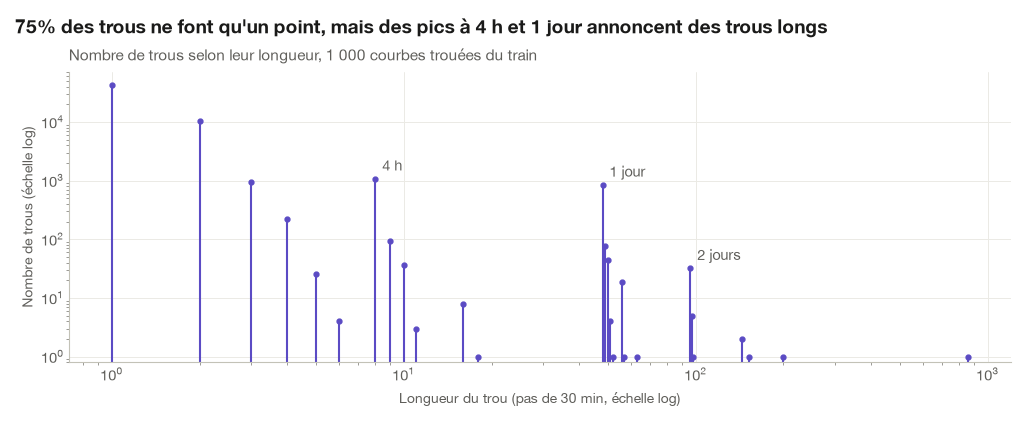

In [12]:
# Liste de tous les trous des 1 000 courbes trouées du train
runs = hole_runs(mask)
runs["courbe"] = X_holed.columns[runs["curve"]]
runs["classe"] = length_bucket(runs["length"])
L = runs["length"].to_numpy()
print(f"{len(runs)} trous, {L.sum()} valeurs manquantes ({mask.mean():.2%} des points)")
print(
    f"Trous de 1 point : {(L == 1).mean():.1%} | ≤ 2 points : {(L <= 2).mean():.1%} | "
    f"> 48 points : {(L > 48).mean():.2%} ({(L > 48).sum()} trous)"
)
longest = runs.loc[runs["length"].idxmax()]
print(
    f"Plus long trou : {L.max()} pas ({longest['courbe']}) ; "
    f"hors cette courbe : {L[runs['curve'] != longest['curve']].max()} pas"
)

# Distribution des longueurs, en échelle log-log
counts = np.bincount(L)
lens = np.flatnonzero(counts)
fig, ax = plt.subplots(figsize=(10, 4))
ax.vlines(lens, 0.8, counts[lens], color=P["data"], lw=1.5)
ax.plot(lens, counts[lens], "o", color=P["data"], ms=3.5)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_ylim(bottom=0.8)
for n, lab in [(8, "4 h"), (48, "1 jour"), (96, "2 jours")]:
    ax.annotate(
        lab, (n, counts[n]), xytext=(5, 6), textcoords="offset points", color=P["ink_secondary"]
    )
ax.set_xlabel("Longueur du trou (pas de 30 min, échelle log)")
ax.set_ylabel("Nombre de trous (échelle log)")
ax.set_title("Nombre de trous selon leur longueur, 1 000 courbes trouées du train")
set_conclusion(
    fig,
    f"{(L == 1).mean():.0%} des trous ne font qu'un point, "
    "mais des pics à 4 h et 1 jour annoncent des trous longs",
)
save_fig(fig, "c1_longueur_trous");

,trous,valeurs,part des trous,part des valeurs manquantes
classe,,,,
1,42031,42031,0.751,0.324
2,10478,20956,0.187,0.161
3-6,1207,3904,0.022,0.030
7-48,2059,50404,0.037,0.388
>48,191,12614,0.003,0.097


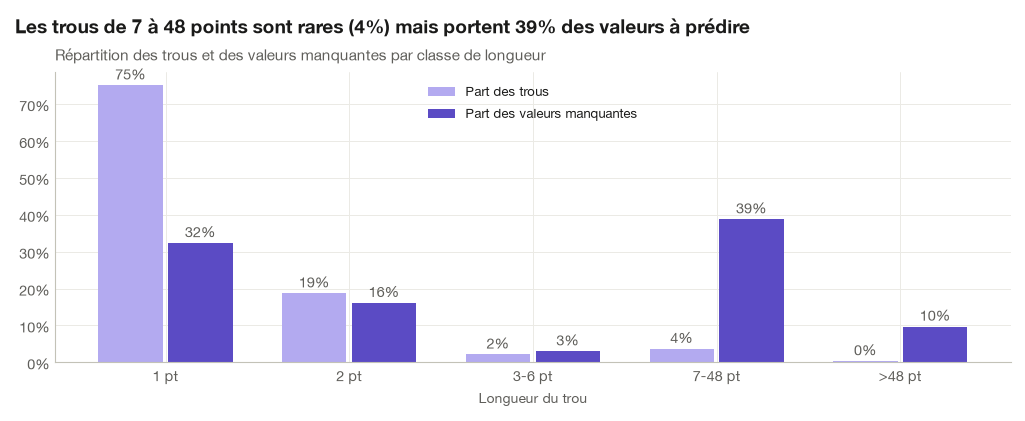

In [13]:
# Nombre de trous ≠ nombre de valeurs manquantes : un trou de 40 points pèse 40 fois plus
# qu'un trou de 1 point dans la MAE.
by_class = runs.groupby("classe", observed=False).agg(
    trous=("length", "size"), valeurs=("length", "sum")
)
by_class["part des trous"] = by_class["trous"] / by_class["trous"].sum()
by_class["part des valeurs manquantes"] = by_class["valeurs"] / by_class["valeurs"].sum()
display(by_class)

fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(LENGTH_LABELS))
w = 0.38
for off, col, color in [
    (-w / 2, "part des trous", P["data_light"]),
    (w / 2, "part des valeurs manquantes", P["data"]),
]:
    bars = ax.bar(x + off, by_class[col], width=w - 0.03, color=color, label=col.capitalize())
    ax.bar_label(
        bars, labels=[f"{v:.0%}" for v in by_class[col]], padding=2, color=P["ink_secondary"]
    )
ax.set_xticks(x, [f"{c} pt" for c in LENGTH_LABELS])
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_xlabel("Longueur du trou")
ax.set_title("Répartition des trous et des valeurs manquantes par classe de longueur")
ax.legend(loc="upper center")
set_conclusion(
    fig,
    f"Les trous de 7 à 48 points sont rares ({by_class.loc['7-48', 'part des trous']:.0%}) "
    f"mais portent {by_class.loc['7-48', 'part des valeurs manquantes']:.0%} "
    "des valeurs à prédire",
)
save_fig(fig, "c2_part_par_longueur");

Taux par pas de temps : min 4.7%, max 16.2%, écart-type 1.13%
Taux par heure : de 11.8% à 12.8%
Taux par jour de semaine : {'lun': 0.122, 'mar': 0.126, 'mer': 0.115, 'jeu': 0.123, 'ven': 0.121, 'sam': 0.127, 'dim': 0.125}
Heure de début des trous ≥ 7 points (part par tranche de 6 h) : {0: 0.596, 6: 0.097, 12: 0.177, 18: 0.129}


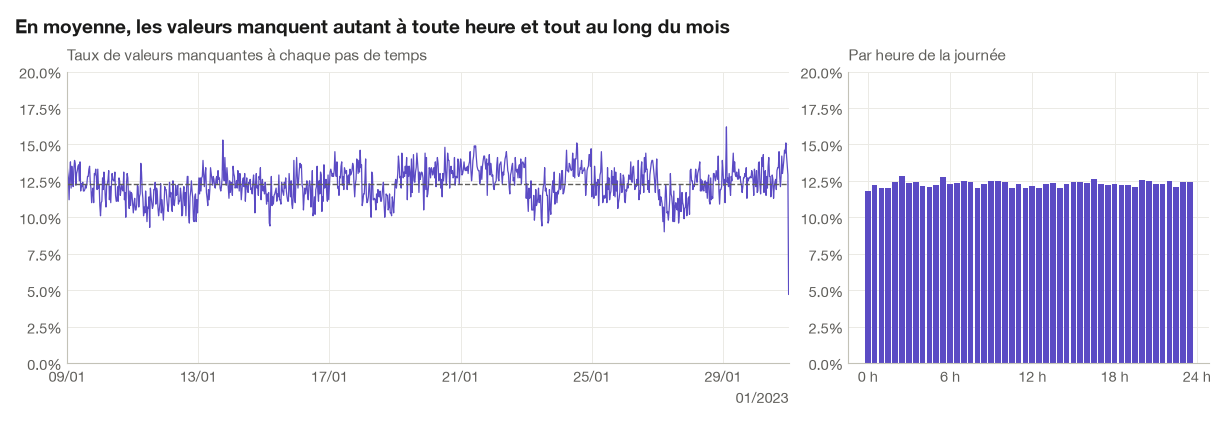

In [14]:
# Position des trous dans le temps : le taux de valeurs manquantes varie-t-il ?
rate_t = pd.Series(mask.mean(axis=1), index=idx)
by_hour = rate_t.groupby(hour).mean()
starts_long = idx[runs.loc[runs["length"] >= 7, "start"].to_numpy()]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4), width_ratios=[2, 1])
ax1.plot(rate_t.index, rate_t.to_numpy(), color=P["data"], lw=0.9)
ax1.axhline(mask.mean(), color=P["ink_secondary"], ls="--", lw=1)
ax1.yaxis.set_major_formatter(PercentFormatter(1))
ax1.set_ylim(0, 0.2)
ax1.set_xlim(idx[0], idx[-1])
ax1.set_title("Taux de valeurs manquantes à chaque pas de temps")
ax2.bar(by_hour.index, by_hour.to_numpy(), width=0.42, color=P["data"])
ax2.yaxis.set_major_formatter(PercentFormatter(1))
ax2.set_ylim(0, 0.2)
ax2.set_xticks(range(0, 25, 6), [f"{h} h" for h in range(0, 25, 6)])
ax2.set_title("Par heure de la journée")
set_conclusion(fig, "En moyenne, les valeurs manquent autant à toute heure et tout au long du mois")
save_fig(fig, "c3_position_temporelle")
print(
    f"Taux par pas de temps : min {rate_t.min():.1%}, max {rate_t.max():.1%}, "
    f"écart-type {rate_t.std():.2%}"
)
print(f"Taux par heure : de {by_hour.min():.1%} à {by_hour.max():.1%}")
print(
    "Taux par jour de semaine :",
    rate_t.groupby(idx.day_of_week).mean().round(3).set_axis(days_fr).to_dict(),
)
print(
    "Heure de début des trous ≥ 7 points (part par tranche de 6 h) :",
    pd.Series(starts_long.hour // 6 * 6)
    .value_counts(normalize=True)
    .sort_index()
    .round(3)
    .to_dict(),
)

Taux de NaN par courbe : médiane 11.7%, 1 %–99 % : 5.7%–24.1%, max 99.9%
Lien taux de trous ↔ niveau de la courbe (Spearman) : ρ = -0.027 (p = 0.40)
Trous > 48 points : 191 répartis sur 174 courbes (max 2 par courbe)
Courbes avec au moins un trou de 7–48 points : 891 / 1000

Cas extrême : holed_192, 1056 NaN sur 1057, 1 point(s) observé(s) ; vérité y disponible : 1 point(s)


,holed_192,holed_186,holed_638,holed_93,holed_913,holed_800
part manquante,0.999,0.276,0.256,0.253,0.252,0.251


Courbes trouées nulles sur tous leurs points observés : 42 ; vraie valeur max dans leurs trous : 14 W


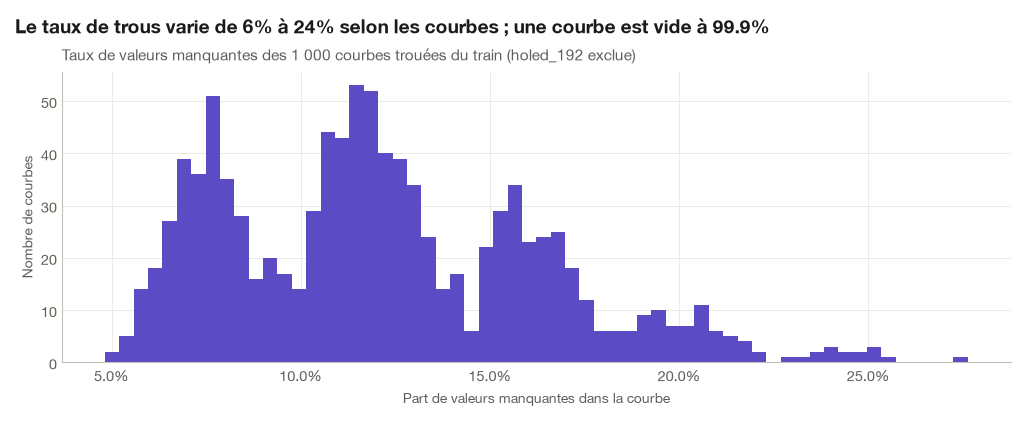

In [15]:
# Taux de trous par courbe et cas extrêmes
rate_c = pd.Series(mask.mean(axis=0), index=X_holed.columns)
lvl_holed = X_holed.mean()
ok = rate_c < 0.9
rho, p = spearmanr(rate_c[ok], lvl_holed[ok])
print(
    f"Taux de NaN par courbe : médiane {rate_c.median():.1%}, "
    f"1 %–99 % : {rate_c.quantile(0.01):.1%}–{rate_c.quantile(0.99):.1%}, max {rate_c.max():.1%}"
)
print(f"Lien taux de trous ↔ niveau de la courbe (Spearman) : ρ = {rho:.3f} (p = {p:.2f})")
n_long = runs[runs["length"] > 48].groupby("courbe").size()
print(
    f"Trous > 48 points : {n_long.sum()} répartis sur {len(n_long)} courbes "
    f"(max {n_long.max()} par courbe)"
)
print(
    "Courbes avec au moins un trou de 7–48 points : "
    f"{runs.loc[runs['classe'] == '7-48', 'courbe'].nunique()} / 1000"
)

worst = rate_c.idxmax()
w_mask = mask[:, X_holed.columns.get_loc(worst)]
print(
    f"\nCas extrême : {worst}, {w_mask.sum()} NaN sur {len(idx)}, {(~w_mask).sum()} point(s) "
    f"observé(s) ; vérité y disponible : {y[worst].notna().sum()} point(s)"
)
display(rate_c.sort_values(ascending=False).head(6).to_frame("part manquante").T)

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(rate_c[ok], bins=60, color=P["data"])
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set_xlabel("Part de valeurs manquantes dans la courbe")
ax.set_ylabel("Nombre de courbes")
ax.set_title(f"Taux de valeurs manquantes des 1 000 courbes trouées du train ({worst} exclue)")
set_conclusion(
    fig,
    f"Le taux de trous varie de {rate_c.quantile(0.01):.0%} à {rate_c.quantile(0.99):.0%} "
    f"selon les courbes ; une courbe est vide à {rate_c.max():.1%}",
)
save_fig(fig, "c4_taux_par_courbe")
zero_holed = X_holed.columns[X_holed.abs().max() == 0]
print(
    f"Courbes trouées nulles sur tous leurs points observés : {len(zero_holed)} ; "
    "vraie valeur max dans leurs trous : "
    f"{np.nanmax(y[zero_holed].where(X_holed[zero_holed].isna()).to_numpy()):.0f} W"
)

,nb de trous,début sur une heure pile,début sur 0h/4h/8h/12h/16h/20h,début à minuit
longueur du trou,,,,
1,"42,031.000",0.500,0.124,0.021
2,"10,478.000",0.904,0.218,0.032
3,958.000,0.478,0.122,0.016
4,219.000,0.904,0.237,0.037
8,"1,073.000",1.000,1.000,0.162
9,95.000,0.442,0.442,0.084
48,842.000,1.000,1.000,1.000
49,77.000,0.545,0.545,0.545
96,32.000,1.000,1.000,1.000


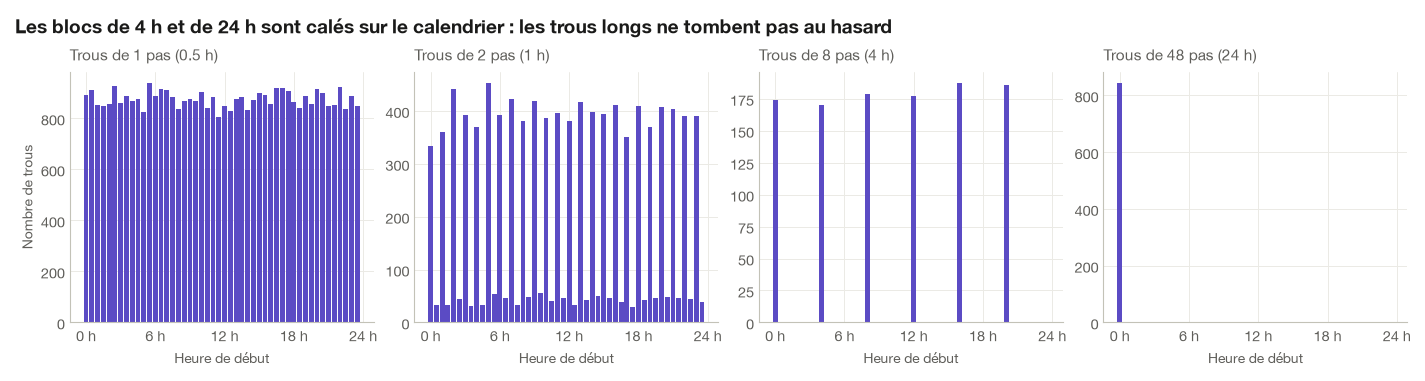

In [16]:
# Les trous longs sont-ils placés au hasard ? On regarde à quel créneau de la journée
# (0 = 00:00, 1 = 00:30, …, 47 = 23:30) commence chaque trou, selon sa longueur.
start_idx = idx[runs["start"].to_numpy()]
runs["créneau"] = start_idx.hour * 2 + start_idx.minute // 30
align = pd.DataFrame(
    {
        n: {
            "nb de trous": (r := runs[runs["length"] == n]).shape[0],
            "début sur une heure pile": (r["créneau"] % 2 == 0).mean(),
            "début sur 0h/4h/8h/12h/16h/20h": (r["créneau"] % 8 == 0).mean(),
            "début à minuit": (r["créneau"] == 0).mean(),
        }
        for n in [1, 2, 3, 4, 8, 9, 48, 49, 96]
    }
).T.rename_axis("longueur du trou")
display(align)

fig, axes = plt.subplots(1, 4, figsize=(14, 3.6), sharex=True)
for ax, n in zip(axes, [1, 2, 8, 48], strict=True):
    cnt = runs.loc[runs["length"] == n, "créneau"].value_counts().reindex(range(48), fill_value=0)
    ax.bar(np.arange(48) / 2, cnt.to_numpy(), width=0.42, color=P["data"])
    ax.set_title(f"Trous de {n} pas ({n / 2:g} h)")
    ax.set_xticks(range(0, 25, 6), [f"{h} h" for h in range(0, 25, 6)])
    ax.set_xlabel("Heure de début")
axes[0].set_ylabel("Nombre de trous")
set_conclusion(
    fig,
    "Les blocs de 4 h et de 24 h sont calés sur le calendrier : "
    "les trous longs ne tombent pas au hasard",
)
save_fig(fig, "c5_alignement_trous");

### Constat → conséquence pour la modélisation

**Constat**
- **12,3 % des points sont manquants**, répartis en 55 966 trous.
  - **75 % des trous font 1 point**, 94 % au plus 2 points.
  - Seuls 0,34 % (191 trous) dépassent 48 points. Le plus long fait 857 pas (`holed_192`), puis 152 pas pour les autres courbes.
- **Compter les trous est trompeur.** Les trous de **7–48 points** ne représentent que **3,7 % des trous** mais **39 % des valeurs à prédire**. Ceux de plus de 48 points en représentent encore 10 %.
- **Le taux global de NaN est uniforme dans le temps** : 11,8 % à 12,8 % selon l'heure, sans effet du jour de la semaine. Il est aussi **indépendant du niveau de la courbe** (ρ de Spearman = −0,03).
- **En revanche, les trous longs sont calés sur le calendrier**. Les données mélangent plusieurs mécanismes :
  - des **points isolés**, placés au hasard ;
  - des **blocs d'1 heure** : 90 % des trous de 2 points commencent sur une heure pile ;
  - des **blocs de 4 h** : 100 % des trous de 8 points commencent à 0 h, 4 h, 8 h, 12 h, 16 h ou 20 h ;
  - des **journées entières** : 100 % des trous de 48 et 96 points commencent à minuit.
  
  Les longueurs 9, 49 ou 50 correspondent à un bloc fusionné avec un point isolé voisin.
- **Taux de NaN par courbe** : médiane 11,7 %, entre 5,7 % et 24,1 % pour 98 % des courbes. Les longs trous sont dispersés : 191 trous de plus de 48 points sur 174 courbes, et 891 courbes sur 1 000 ont au moins un trou de 7–48 points.
- **42 courbes trouées sont nulles sur tous leurs points observés**. Leur vraie valeur dans les trous ne dépasse pas 14 W.

**→ Conséquence**
- **Protocole de validation** : les faux trous devront reproduire ces **mécanismes** (points isolés, blocs horaires, blocs de 4 h, journées à minuit) dans les mêmes proportions. Tirer des longueurs au hasard ne suffit pas.
- **L'optimisation doit viser les trous longs** : ils pèsent la moitié des valeurs à prédire. Pour des trous alignés sur minuit, le jour d'avant et le jour d'après de la même courbe sont des sources d'information naturelles.
- L'absence de lien entre trous et niveau ou heure indique un mécanisme de type *missing completely at random* (MCAR) en intensité : pas de biais de sélection à corriger.
- Règle simple à valider : prédire 0 pour une courbe nulle sur tous ses points observés. `holed_192` (1 point observé) demandera un repli, par exemple un profil moyen.

## d. Train vs test

In [17]:
# Mêmes statistiques sur le test
T_runs = hole_runs(T_mask)
T_runs["classe"] = length_bucket(T_runs["length"])
TL = T_runs["length"].to_numpy()


def summary(F: pd.DataFrame, H: pd.DataFrame, m: np.ndarray, r: pd.DataFrame) -> dict[str, float]:
    """Statistiques clés d'un jeu (courbes complètes F, trouées H, masque m, trous r)."""
    ln = r["length"].to_numpy()
    out = {
        "courbes complètes": F.shape[1],
        "niveau médian complètes (W)": F.mean().median(),
        "part courbes complètes nulles": (F.abs().max() == 0).mean(),
        "niveau médian trouées (W)": H.mean().median(),
        "taux de NaN (trouées)": m.mean(),
        "nb de trous": len(r),
        "part trous 1 pt": (ln == 1).mean(),
        "part trous ≤ 2 pts": (ln <= 2).mean(),
        "part trous > 48 pts": (ln > 48).mean(),
        "plus long trou": ln.max(),
    }
    share = r.groupby("classe", observed=False)["length"].sum() / ln.sum()
    out |= {f"part valeurs manquantes {c} pt": v for c, v in share.items()}
    return out


cmp = pd.DataFrame(
    {
        "train": summary(X_full, X_holed, mask, runs),
        "test": summary(T_full, T_holed, T_mask, T_runs),
    }
)
display(cmp)

,train,test
courbes complètes,"20,000.000","37,140.000"
niveau médian complètes (W),212.403,211.306
part courbes complètes nulles,0.035,0.037
niveau médian trouées (W),209.519,217.806
taux de NaN (trouées),0.123,0.122
nb de trous,"55,966.000","55,885.000"
part trous 1 pt,0.751,0.752
part trous ≤ 2 pts,0.938,0.938
part trous > 48 pts,0.003,0.004
plus long trou,857.000,144.000


,D de KS,p-valeur
niveau des courbes complètes,0.005,0.888
niveau des courbes trouées,0.048,0.200
taux de NaN par courbe trouée,0.038,0.466
longueur des trous,0.001,1.000


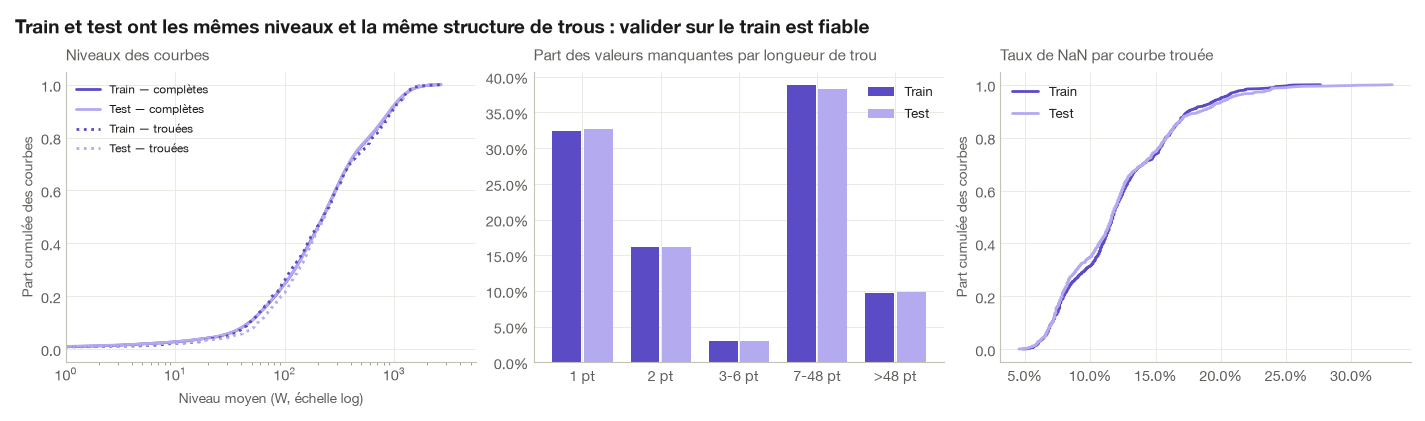

In [18]:
# Tests de Kolmogorov-Smirnov : les distributions diffèrent-elles ?
# (Avec des dizaines de milliers d'observations, la statistique D compte plus que la p-valeur.)
T_levels = T_full.mean()
T_rate_c = T_mask.mean(axis=0)
tests = {
    "niveau des courbes complètes": (levels.dropna(), T_levels.dropna()),
    "niveau des courbes trouées": (lvl_holed.dropna(), T_holed.mean().dropna()),
    "taux de NaN par courbe trouée": (rate_c, T_rate_c),
    "longueur des trous": (L, TL),
}
display(
    pd.DataFrame({k: ks_2samp(a, b)._asdict() for k, (a, b) in tests.items()})
    .T[["statistic", "pvalue"]]
    .rename(columns={"statistic": "D de KS", "pvalue": "p-valeur"})
)


def ecdf(ax: plt.Axes, v: np.ndarray, **kw) -> None:
    """Trace une fonction de répartition empirique."""
    v = np.sort(np.asarray(v))
    ax.plot(v, np.arange(1, len(v) + 1) / len(v), **kw)


fig, axes = plt.subplots(1, 3, figsize=(14, 4))
ax = axes[0]
for v, lab, color, ls in [
    (levels, "Train — complètes", P["data"], "-"),
    (T_levels, "Test — complètes", P["data_light"], "-"),
    (lvl_holed, "Train — trouées", P["data"], ":"),
    (T_holed.mean(), "Test — trouées", P["data_light"], ":"),
]:
    ecdf(ax, v[v > 0].dropna(), color=color, ls=ls, lw=2, label=lab)
ax.set_xscale("log")
ax.set_xlim(left=1)
ax.set_xlabel("Niveau moyen (W, échelle log)")
ax.set_ylabel("Part cumulée des courbes")
ax.set_title("Niveaux des courbes")
ax.legend(fontsize=8.5)
ax = axes[1]
x = np.arange(len(LENGTH_LABELS))
for off, r, lab, color in [
    (-0.2, runs, "Train", P["data"]),
    (0.2, T_runs, "Test", P["data_light"]),
]:
    share = r.groupby("classe", observed=False)["length"].sum() / r["length"].sum()
    ax.bar(x + off, share.to_numpy(), width=0.37, color=color, label=lab)
ax.set_xticks(x, [f"{c} pt" for c in LENGTH_LABELS])
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_title("Part des valeurs manquantes par longueur de trou")
ax.legend()
ax = axes[2]
ecdf(ax, rate_c[ok], color=P["data"], lw=2, label="Train")
ecdf(ax, T_rate_c, color=P["data_light"], lw=2, label="Test")
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set_ylabel("Part cumulée des courbes")
ax.set_title("Taux de NaN par courbe trouée")
ax.legend()
set_conclusion(
    fig,
    "Train et test ont les mêmes niveaux et la même structure de trous : "
    "valider sur le train est fiable",
)
save_fig(fig, "d1_train_vs_test");

### Constat → conséquence pour la modélisation

**Constat**
- Les **niveaux** des courbes complètes sont identiques entre train et test (médiane 212 W contre 211 W, D de KS = 0,005), de même que leur part de courbes nulles (3,5 % contre 3,7 %).
- Les courbes **trouées** ont les mêmes niveaux que les complètes, en train comme en test (D = 0,05, p = 0,20). Elles semblent tirées de la même population.
- La **structure des trous** est quasi identique :
  - taux de NaN de 12,3 % contre 12,2 % ;
  - mêmes parts par classe de longueur, à 0,5 point près ;
  - D = 0,001 sur la longueur des trous et 0,04 sur le taux par courbe.
  
  Les mêmes mécanismes calés sur le calendrier se retrouvent dans le test.
- Seule différence : le test n'a pas de courbe extrême comme `holed_192`. Son plus long trou fait 144 pas.
- Le test offre **1,86 fois plus de courbes complètes** (37 140 contre 20 000), donc plus de voisins potentiels.

**→ Conséquence**
- Une validation sur le train, avec la vraie vérité `y_train` **et** des faux trous simulés, sera **représentative du score test**.
- En test, chercher les voisins parmi les courbes complètes du test, et même parmi celles de train + test, puisque les distributions sont identiques. Un réservoir plus grand donne des voisins plus proches.
- Aucun ajustement de distribution (*domain shift*) n'est nécessaire.

## e. Erreur du benchmark (interpolation linéaire)

In [19]:
# Benchmark officiel : interpolation linéaire, extrapolée par constante aux bords
interp = X_holed.interpolate(limit_direction="both")
interp_arr = interp.to_numpy()
print(f"MAE globale de l'interpolation linéaire : {mae_on_holes(interp, y, mask):.2f} W")

# Erreur par longueur du trou auquel appartient chaque point manquant
point_len = hole_length_per_point(mask)
valid = mask & ~np.isnan(y_arr)  # positions évaluées (on exclut les NaN de y)
err = np.abs(interp_arr[valid] - y_arr[valid])
pts = pd.DataFrame({"longueur": point_len[valid], "erreur": err})
pts["classe"] = length_bucket(pts["longueur"])

by_cls = pts.groupby("classe", observed=False)["erreur"].agg(points="size", MAE="mean", somme="sum")
by_cls["part des points"] = by_cls["points"] / by_cls["points"].sum()
by_cls["part de l'erreur totale"] = by_cls["somme"] / by_cls["somme"].sum()
display(by_cls.drop(columns="somme"))

MAE globale de l'interpolation linéaire : 101.95 W


,points,MAE,part des points,part de l'erreur totale
classe,,,,
1,42031,62.095,0.326,0.199
2,20956,71.188,0.163,0.114
3-6,3904,78.669,0.030,0.023
7-48,50404,139.821,0.391,0.536
>48,11558,145.381,0.090,0.128


fine,1,2,3-4,5-8,9-16,17-48,49-96,>96
MAE,62.095,71.188,79.079,98.143,119.233,149.262,141.544,184.895
points,"42,031.000","20,956.000","3,750.000","8,738.000","1,386.000","40,434.000","10,535.000","1,023.000"


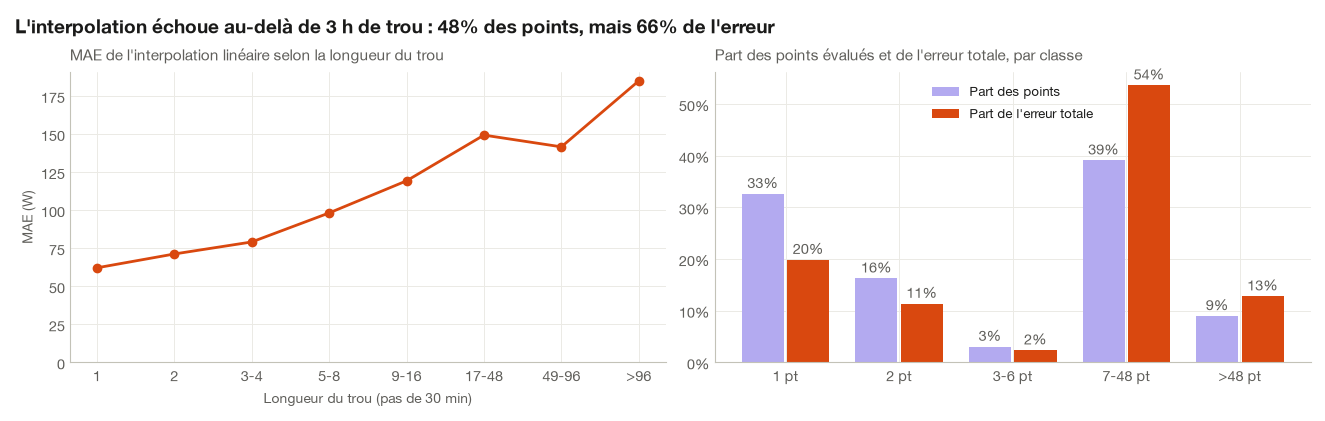

In [20]:
# MAE selon la longueur exacte du trou, et contribution de chaque classe
# Classes de longueur fines, en progression géométrique, pour une courbe lisible
fine_bins = [0, 1, 2, 4, 8, 16, 48, 96, np.inf]
fine_labels = ["1", "2", "3-4", "5-8", "9-16", "17-48", "49-96", ">96"]
by_len = (
    pts.assign(fine=pd.cut(pts["longueur"], fine_bins, labels=fine_labels))
    .groupby("fine", observed=False)["erreur"]
    .agg(["mean", "size"])
)
display(by_len.rename(columns={"mean": "MAE", "size": "points"}).T)
long_cls = ["7-48", ">48"]
pts_long = by_cls.loc[long_cls, "part des points"].sum()
err_long = by_cls.loc[long_cls, "part de l'erreur totale"].sum()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
ax1.plot(fine_labels, by_len["mean"], color=method_color("interpolation"), marker="o", ms=6, lw=2)
ax1.set_xlabel("Longueur du trou (pas de 30 min)")
ax1.set_ylabel("MAE (W)")
ax1.set_ylim(bottom=0)
ax1.set_title("MAE de l'interpolation linéaire selon la longueur du trou")
x = np.arange(len(LENGTH_LABELS))
for off, col, color in [
    (-0.2, "part des points", P["data_light"]),
    (0.2, "part de l'erreur totale", method_color("interpolation")),
]:
    bars = ax2.bar(x + off, by_cls[col], width=0.37, color=color, label=col.capitalize())
    ax2.bar_label(
        bars, labels=[f"{v:.0%}" for v in by_cls[col]], padding=2, color=P["ink_secondary"]
    )
ax2.set_xticks(x, [f"{c} pt" for c in LENGTH_LABELS])
ax2.yaxis.set_major_formatter(PercentFormatter(1))
ax2.set_title("Part des points évalués et de l'erreur totale, par classe")
ax2.legend(loc="upper center")
set_conclusion(
    fig,
    f"L'interpolation échoue au-delà de 3 h de trou : {pts_long:.0%} des points, "
    f"mais {err_long:.0%} de l'erreur",
)
save_fig(fig, "e1_mae_par_longueur");

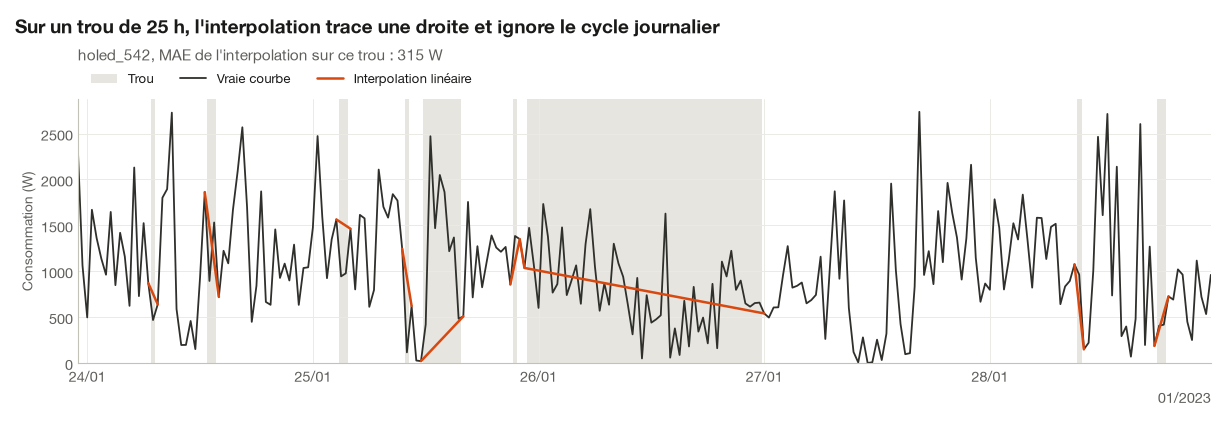

In [21]:
# Exemple : un long trou mal rempli par l'interpolation
runs["mae_interp"] = [
    np.nanmean(np.abs(interp_arr[s : s + n, c] - y_arr[s : s + n, c]))
    if not np.isnan(y_arr[s : s + n, c]).all()
    else np.nan
    for c, s, n in zip(runs["curve"], runs["start"], runs["length"], strict=True)
]
long = runs[(runs["length"] > 48) & runs["mae_interp"].notna()]
# Cas représentatif d'un échec : le long trou dont l'erreur est la plus proche du 90e centile
ex = long.loc[(long["mae_interp"] - long["mae_interp"].quantile(0.9)).abs().idxmin()]
c, s, n = int(ex["curve"]), int(ex["start"]), int(ex["length"])
col = X_holed.columns[c]

fig = plot_imputation(
    y[col],
    {"Interpolation linéaire": interp[col]},
    mask[:, c],
    f"Sur un trou de {n / 2:.0f} h, l'interpolation trace une droite et ignore le cycle journalier",
    window=slice(max(0, s - 96), min(len(idx), s + n + 96)),  # 2 jours de contexte
)
fig.axes[0].set_title(
    f"{col}, MAE de l'interpolation sur ce trou : {ex['mae_interp']:.0f} W", pad=28
)
save_fig(fig, "e2_long_trou_interpolation");

### Constat → conséquence pour la modélisation

**Constat**
- **MAE globale de l'interpolation linéaire : 101,95 W**, ce qui reproduit le benchmark officiel.
- La MAE augmente avec la longueur du trou :

  | Longueur du trou | MAE |
  |---|---|
  | 1 point | 62 W |
  | 2 points | 71 W |
  | 3–6 points | 79 W |
  | 7–48 points | **140 W** |
  | plus de 48 points | **145 W** |

  Plus finement, l'erreur passe de 62 W (1 point) à 98 W (5–8 points), puis à ~145 W entre 17 et 96 points, et à 185 W au-delà de 2 jours. Sur un trou long, l'interpolation ne fait guère mieux qu'une constante.
- **D'où vient l'erreur** : les trous de 7 points et plus représentent 48 % des points évalués mais **66 % de l'erreur totale**. La classe 7–48 seule en produit 54 %.
- L'exemple montre l'échec type : sur un trou d'environ une journée (une journée calée sur minuit, plus un point voisin), l'interpolation trace une simple droite entre les deux bords. Elle ignore tout le cycle journalier.

**→ Conséquence**
- Le gain potentiel est **sur les trous longs**. Diviser par deux l'erreur de la classe 7–48 ferait gagner ~27 % de MAE globale.
- Garder l'interpolation (ou un modèle local) pour les trous courts, où elle est difficile à battre, et **combiner les méthodes selon la longueur du trou**. Une simple moyenne 50/50 donne déjà ≈ 92 W.
- Évaluer systématiquement **par classe de longueur**, et pas seulement globalement.

## f. Les courbes se ressemblent-elles ?

In [22]:
# Courbes complètes de référence : on écarte la seule courbe de train qui contient des NaN.
ref = X_full.loc[:, X_full.notna().all()].to_numpy()
print("Courbes de référence :", ref.shape[1])


def nearest(
    x: np.ndarray, obs: np.ndarray, k: int = 5, block: int = 5000
) -> tuple[np.ndarray, np.ndarray]:
    """Les k courbes de référence les plus proches de x, en MAE sur ses points observés.

    Le calcul se fait par blocs de colonnes pour ne jamais créer de matrice géante.
    Renvoie (indices triés, toutes les distances).
    """
    xo = x[obs][:, None]
    dist = np.empty(ref.shape[1], dtype=np.float32)
    for j in range(0, ref.shape[1], block):
        dist[j : j + block] = np.abs(ref[obs, j : j + block] - xo).mean(axis=0)
    return np.argsort(dist)[:k], dist

Courbes de référence : 19999


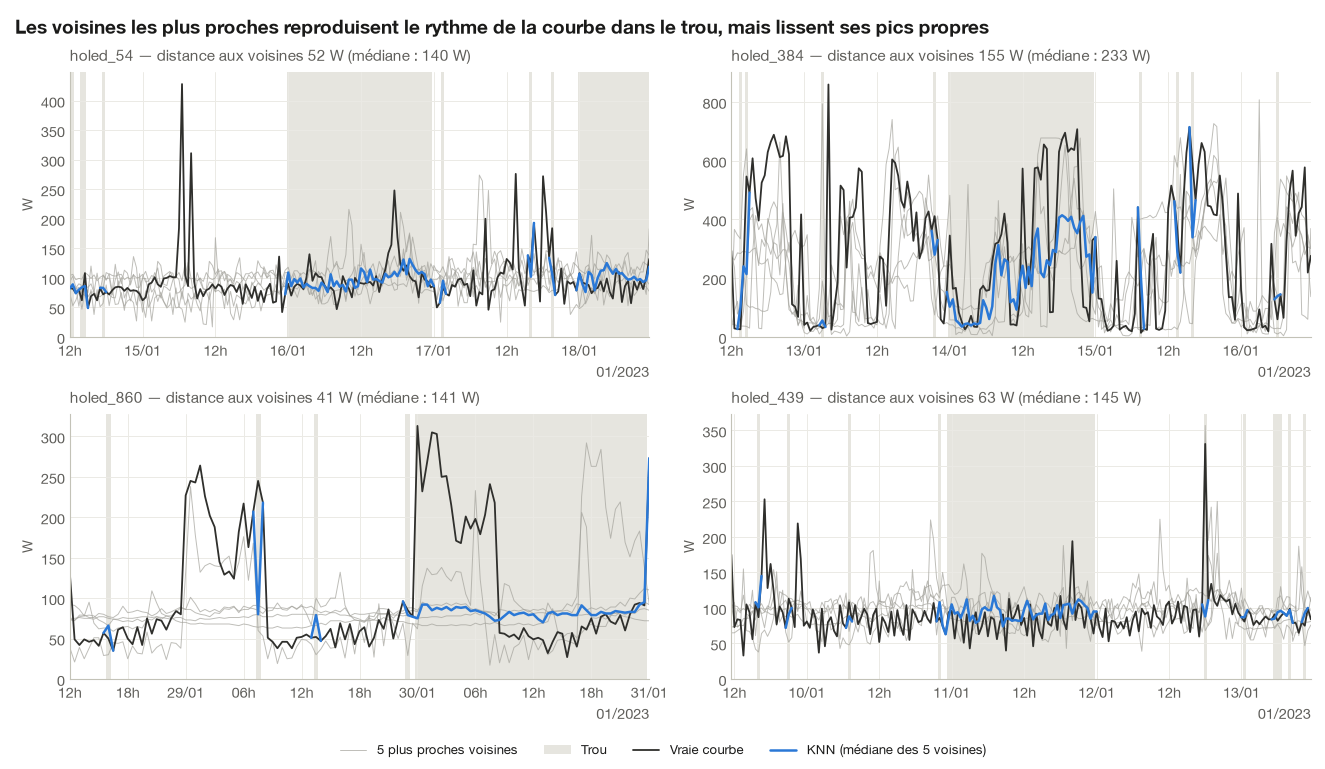

In [23]:
# 4 courbes trouées tirées au hasard parmi celles qui ont un trou d'au moins 24 points (12 h)
cands = runs[(runs["length"] >= 24) & runs["mae_interp"].notna()].drop_duplicates("curve")
picked = cands.iloc[rng.choice(len(cands), 4, replace=False)]

fig, axes = plt.subplots(2, 2, figsize=(13, 7.5))
for ax, (_, h) in zip(axes.flat, picked.iterrows(), strict=True):
    c, s, n = int(h["curve"]), int(h["start"]), int(h["length"])
    nn, dist = nearest(X_holed.iloc[:, c].to_numpy(), ~mask[:, c])
    win = slice(max(0, s - 72), min(len(idx), s + n + 72))
    for i, j in enumerate(nn):  # les 5 voisines, en fond
        ax.plot(
            idx[win],
            ref[win, j],
            color=P["neutral"],
            lw=0.7,
            alpha=0.7,
            label="5 plus proches voisines" if i == 0 else None,
        )
    plot_imputation(
        y.iloc[:, c],
        {"KNN (médiane des 5 voisines)": np.median(ref[:, nn], axis=1)},
        mask[:, c],
        f"{h['courbe']} — distance aux voisines {dist[nn].mean():.0f} W "
        f"(médiane : {np.median(dist):.0f} W)",
        window=win,
        ax=ax,
        legend=False,
    )
    ax.set_ylabel("W")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=len(labels))
set_conclusion(
    fig,
    "Les voisines les plus proches reproduisent le rythme de la courbe dans le trou, "
    "mais lissent ses pics propres",
)
save_fig(fig, "f1_voisins");

Distance aux 5 voisines / distance médiane : médiane 0.35 (les voisines sont ~2.9× plus proches qu'une courbe quelconque)


,KNN (médiane de 5),Interpolation
MAE (W) par classe de trou,,
1,110.394,65.422
2,111.837,76.752
3-6,110.932,78.534
7-48,105.751,131.693
>48,98.817,128.544
toutes,107.982,98.931


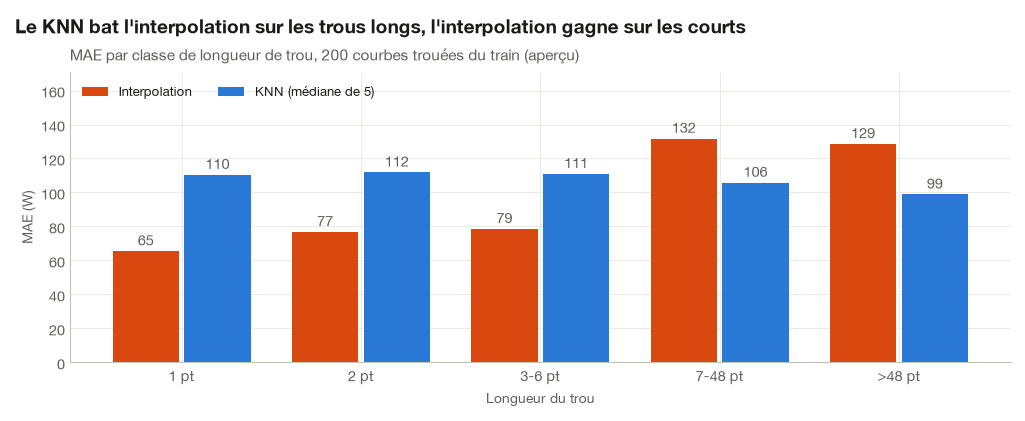

In [24]:
# Aperçu chiffré sur 200 courbes trouées tirées au hasard (pas une évaluation : ce sera
# l'étape KNN, avec un protocole de validation propre).
sub_cols = rng.choice(np.flatnonzero(ok.to_numpy()), 200, replace=False)
rows, ratios = [], []
for c in sub_cols:
    nn, dist = nearest(X_holed.iloc[:, c].to_numpy(), ~mask[:, c])
    knn = np.median(ref[:, nn], axis=1)
    v = valid[:, c]
    rows.append(
        pd.DataFrame(
            {
                "classe": length_bucket(point_len[v, c]),
                "KNN (médiane de 5)": np.abs(knn[v] - y_arr[v, c]),
                "Interpolation": np.abs(interp_arr[v, c] - y_arr[v, c]),
            }
        )
    )
    ratios.append(dist[nn].mean() / np.median(dist))
all_rows = pd.concat(rows)
cmp_knn = all_rows.groupby("classe", observed=False).mean()
cmp_knn.loc["toutes"] = all_rows[["KNN (médiane de 5)", "Interpolation"]].mean()
print(
    f"Distance aux 5 voisines / distance médiane : médiane {np.median(ratios):.2f} "
    f"(les voisines sont ~{1 / np.median(ratios):.1f}× plus proches qu'une courbe quelconque)"
)
display(cmp_knn.rename_axis("MAE (W) par classe de trou"))

fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(LENGTH_LABELS))
for off, col in [(-0.2, "Interpolation"), (0.2, "KNN (médiane de 5)")]:
    bars = ax.bar(
        x + off, cmp_knn.loc[LENGTH_LABELS, col], width=0.37, color=method_color(col), label=col
    )
    ax.bar_label(bars, fmt="%.0f", padding=2, color=P["ink_secondary"])
ax.set_xticks(x, [f"{c} pt" for c in LENGTH_LABELS])
ax.set_xlabel("Longueur du trou")
ax.set_ylabel("MAE (W)")
ax.set_title("MAE par classe de longueur de trou, 200 courbes trouées du train (aperçu)")
ax.set_ylim(0, cmp_knn.loc[LENGTH_LABELS].to_numpy().max() * 1.3)
ax.legend(loc="upper left", ncol=2)
set_conclusion(
    fig, "Le KNN bat l'interpolation sur les trous longs, l'interpolation gagne sur les courts"
)
save_fig(fig, "f2_knn_vs_interp_apercu");

### Constat → conséquence pour la modélisation

**Constat**
- Les 5 plus proches voisines d'une courbe trouée, mesurées en MAE sur ses points observés, sont **~3 fois plus proches qu'une courbe quelconque** (rapport médian 0,35 sur 200 courbes).
- Sur les exemples tracés, la médiane des voisines reproduit le cycle journalier et le niveau à l'intérieur du trou, là où l'interpolation trace une droite.
- Elle a deux limites visibles :
  - elle **lisse les pics** (la médiane écrase les variations propres à chaque client) ;
  - elle ne sait pas prédire un comportement propre à la courbe (`holed_860` : des pics de consommation absents des voisines).
- **Aperçu chiffré sur 200 courbes** (pas encore une évaluation rigoureuse) :

  | Longueur du trou | KNN | Interpolation |
  |---|---|---|
  | 1 point | 110 W | **65 W** |
  | 7–48 points | **106 W** | 132 W |
  | plus de 48 points | **99 W** | 129 W |

  Le **KNN perd largement sur les trous courts mais gagne sur les longs**, d'où un score global similaire. C'est exactement ce que montrait la moyenne 50/50.

**→ Conséquence**
- **L'approche KNN est justifiée**, et elle est **complémentaire** de l'interpolation : il faut les combiner **selon la longueur du trou** plutôt qu'à poids fixe.
- Pistes d'amélioration du KNN :
  - chercher les voisins sur les points **proches du trou** plutôt que sur toute la courbe ;
  - travailler sur des courbes normalisées puis remettre au niveau de la cible ;
  - utiliser une moyenne pondérée par la distance ;
  - élargir le réservoir de voisins aux courbes du test.
- Les voisines (médiane, dispersion) seront aussi d'excellentes **variables d'entrée pour le LightGBM**.

## Synthèse

1. **Les données sont propres et cohérentes.**
   - 1 057 pas de 30 min, mêmes horodates en train et en test.
   - NaN parasites limités à 5 courbes « complètes », à écarter.
   - Les NaN de `y_train` viennent tous de `holed_192`, vide à 99,9 %.
   - Le cache `.npy` charge tout en ~0,1 s, avec ~360 Mo de RAM.
2. **Les courbes ont une mémoire courte mais un rythme journalier fort.** L'autocorrélation vaut 0,71 à 30 min, 0,07 à 6 h, puis remonte à 0,46 à 24 h. Le profil journalier est commun à tous les clients (creux à 4 h 30, pic à 19 h), et une composante météo commune fait varier la consommation de ~30 % d'un jour à l'autre.
3. **Compter les trous est trompeur.** 75 % des trous font 1 point, mais les trous de 7–48 points (3,7 % des trous) portent **39 % des valeurs à prédire** et **54 % de l'erreur** du benchmark.
4. **Les trous suivent des mécanismes calés sur le calendrier** : points isolés aléatoires, blocs d'1 h, blocs de 4 h (0 h/4 h/…/20 h), journées entières à minuit. En revanche, ils ne dépendent ni de l'heure ni du niveau de la courbe. Le protocole de validation devra **reproduire ces mécanismes**.
5. **Le train est représentatif du test** : mêmes niveaux, mêmes structures de trous (D de KS ≤ 0,05). La validation sur le train sera fiable, et le test offre 1,9 fois plus de voisins potentiels.
6. **L'interpolation linéaire (101,95 W) est forte sur les trous courts** (62 W sur 1 point), **mais plafonne à ~140 W sur les trous longs**, où elle ignore le cycle journalier.
7. **Les courbes se ressemblent : le KNN est pertinent et complémentaire.** Les voisines sont ~3 fois plus proches qu'une courbe quelconque. Le KNN bat l'interpolation sur les trous longs (~100 W contre ~130 W) et perd sur les courts (~110 W contre ~65 W).
8. **Stratégie qui en découle** :
   - choisir la méthode **selon la longueur du trou** : interpolation ou modèle local pour les trous courts, information « même heure » (veille, lendemain, voisines) pour les trous longs ;
   - avec un LightGBM qui apprend cet arbitrage ;
   - en raisonnant en niveaux relatifs, car les niveaux sont très hétérogènes.